# Chapter 5: Symbolic derivation

This notebook reproduces the chapter's examples with `geomech` and gives you a place to start the exercises.
The order is: derive the quadrotor with a cable-suspended load, check it, plant a sign error, simulate it,
compare with the thesis equations, then watch the spherical pendulum go through the pipeline stage by stage,
and finish with a chain of n links.

In [1]:
try:
    import geomech
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "geomech==1.1.0"])
    import geomech

import io
import logging

import matplotlib.pyplot as plt
import numpy as np

print("geomech", geomech.__version__)

geomech 1.1.0


## 1. Seventeen lines (Section 5.1)

Declare the variables by manifold, write $L$ and $\delta W$, derive, check.

In [2]:
from geomech import *

half = Scalar("0.5", value=0.5, attr=["Constant"])
mQ, mL, g, l = getScalars("m_Q m_L g l", attr=["Constant"])
J = Matrix("J", attr=["Constant", "SymmetricMatrix"])
e3 = Vector("e3", attr=["Constant"])
xL, q, R = Vector("x_L"), S2("q"), SO3("R")     # load, cable direction, attitude
f, tau = Scalar("f"), Vector("\\tau")          # thrust, torque
omega, xi = q.get_tangent_vector(), q.get_variation_vector()
Omega, eta = R.get_tangent_vector(), R.get_variation_vector()

xQ = xL - q * l                                 # quadrotor: one cable length up
vQ, vL = xQ.t_diff(), xL.t_diff()
L = (half * mQ * Dot(vQ, vQ) + half * mL * Dot(vL, vL)
     + half * Dot(Omega, J * Omega) - mQ * g * Dot(e3, xQ) - mL * g * Dot(e3, xL))
dW = Dot(xL.delta() - Cross(xi, q) * l, (R * e3) * f) + Dot(eta, tau)

variables, inputs = SystemVariables(vectors=[xL, q], matrices=[R]), [f, tau]
eom = compute_eom(L, dW, variables)
err = check_eom(L, dW, variables, eom, inputs=inputs)

print_eom(eom)
print("check_eom error:", err)

\int \delta x_L \cdot \left(-m_Q \ddot{x_L} + m_Q l \left(\dot{\omega_{q}} \times q\right) -\left(\omega_{q} \cdot \omega_{q}\right) m_Q l q -m_L \ddot{x_L} -m_Q g e3 -m_L g e3 + f R e3\right) \, dt = 0
\int \xi_{q} \cdot \left(m_Q l \left(\left(\omega_{q} \times q\right) \times \dot{x_L}\right) + m_Q l \left(q \times \ddot{x_L}\right) -m_Q l l \left(q \times \left(\dot{\omega_{q}} \times q\right)\right) -2 m_Q l \left(\omega_{q} \times \left(q \times \dot{x_L}\right)\right) + m_Q l \left(q \times \left(\omega_{q} \times \dot{x_L}\right)\right) + m_Q g l \left(q \times e3\right) -l f \left(q \times \left(R e3\right)\right)\right) \, dt = 0
\int \eta_{R} \cdot \left(-J \dot{\Omega_{R}} -\Omega_{R} \times \left(J \Omega_{R}\right) + \tau\right) \, dt = 0
check_eom error: 4.059809332153562e-08


`print_eom` prints LaTeX source, one line per variation. Each line is $\int (\text{variation}) \cdot E_\xi\,\mathrm{d}t = 0$,
so the equation of motion is $E_\xi = 0$ with $E_\xi = -(\text{Euler-Lagrange expression}) + \text{forcing}$.
The equation for $\xi_q$ only holds on the tangent plane at $q$.

## 2. Trust, but verify (Section 5.4)

Type the load equation by hand, once with each sign of the centripetal term. `check_eom` compares each with a
finite-difference Euler-Lagrange residual at random states.

In [3]:
aL, domega = xL.t_diff().t_diff(), omega.t_diff()


def load_equation(sign):            # the x_L row, typed in from a page of algebra
    return ((aL + e3 * g) * (mQ + mL) * (-1) + Cross(domega, q) * (mQ * l)
            + q * (Dot(omega, omega) * mQ * l) * sign + (R * e3) * f)


for sign in (-1, +1):
    hand = dict(eom)
    hand[str(xL.delta())] = (xL.delta(), load_equation(sign))
    print(sign, check_eom(L, dW, variables, hand, inputs=inputs))

-1 4.059809332153562e-08
1 1.9027858460945652


In [4]:
hand[str(xL.delta())] = (xL.delta(), load_equation(+1))
try:
    assert_eom(L, dW, variables, hand, inputs=inputs)
except AssertionError as exc:
    print("assert_eom:", exc)

assert_eom: equation for '\delta{x_L}' disagrees with the Euler-Lagrange residual: relative error 1.903e+00 >= 1.0e-05


The three velocity terms in the cable equation add up to a vector along $q$, which is not part of the equation.

In [5]:
rng = np.random.default_rng(0)
qv = rng.normal(size=3)
qv /= np.linalg.norm(qv)
wv = np.cross(qv, rng.normal(size=3))
vv = rng.normal(size=3)
bracket = np.cross(np.cross(wv, qv), vv) - 2 * np.cross(wv, np.cross(qv, vv)) + np.cross(qv, np.cross(wv, vv))
print("bracket          :", bracket)
print("-(omega . v) q   :", -(wv @ vv) * qv)

bracket          : [-0.12569177  0.13206446 -0.64022679]
-(omega . v) q   : [-0.12569177  0.13206446 -0.64022679]


## 3. From equations to motion (Section 5.5)

Standard form $M\,\dot v + b + G\,u = 0$, a generated NumPy module, and a Lie-group integrator.

In [6]:
from geomech.codegen import StateLayout, collect_params, load_module, module_source
from geomech.simulation import simulate

sf = to_standard_form(eom, variables, inputs)
layout = StateLayout(variables, inputs, collect_params([L, dW], variables, inputs))
plant = load_module(module_source(sf, layout, lagrangian=L), "quadrotor_load")

p = {"m_Q": 1.5, "m_L": 0.3, "l": 1.0, "g": 9.81,
     "J": np.diag([0.02, 0.025, 0.04]), "e3": np.array([0.0, 0.0, 1.0])}
q0 = np.array([np.sin(0.8), 0.0, -np.cos(0.8)])     # cable swung out by 0.8 rad
w0 = np.cross(q0, np.cross([0.0, 0.0, 1.6], q0))    # circling about the vertical
v_cm = np.array([0.45, 0.0, 0.0])                   # center-of-mass velocity
v0 = v_cm + p["m_Q"] * p["l"] / (p["m_Q"] + p["m_L"]) * np.cross(w0, q0)
x0 = layout.pack(x_L=np.zeros(3), q=q0, R=np.eye(3), omega_q=w0, x_L_dot=v0)

hover = np.r_[(p["m_Q"] + p["m_L"]) * p["g"], 0.0, 0.0, 0.0]     # u = [f, tau]
traj = simulate(plant, x0, 6.0, p, u=hover)
free = simulate(plant, x0, 6.0, p)                  # no inputs: energy is conserved
E = free.energy()
print(np.max(np.abs(E - E[0])) / abs(E[0]), free.max_drift())

1.0380974234981515e-12 2.3669954885008337e-13


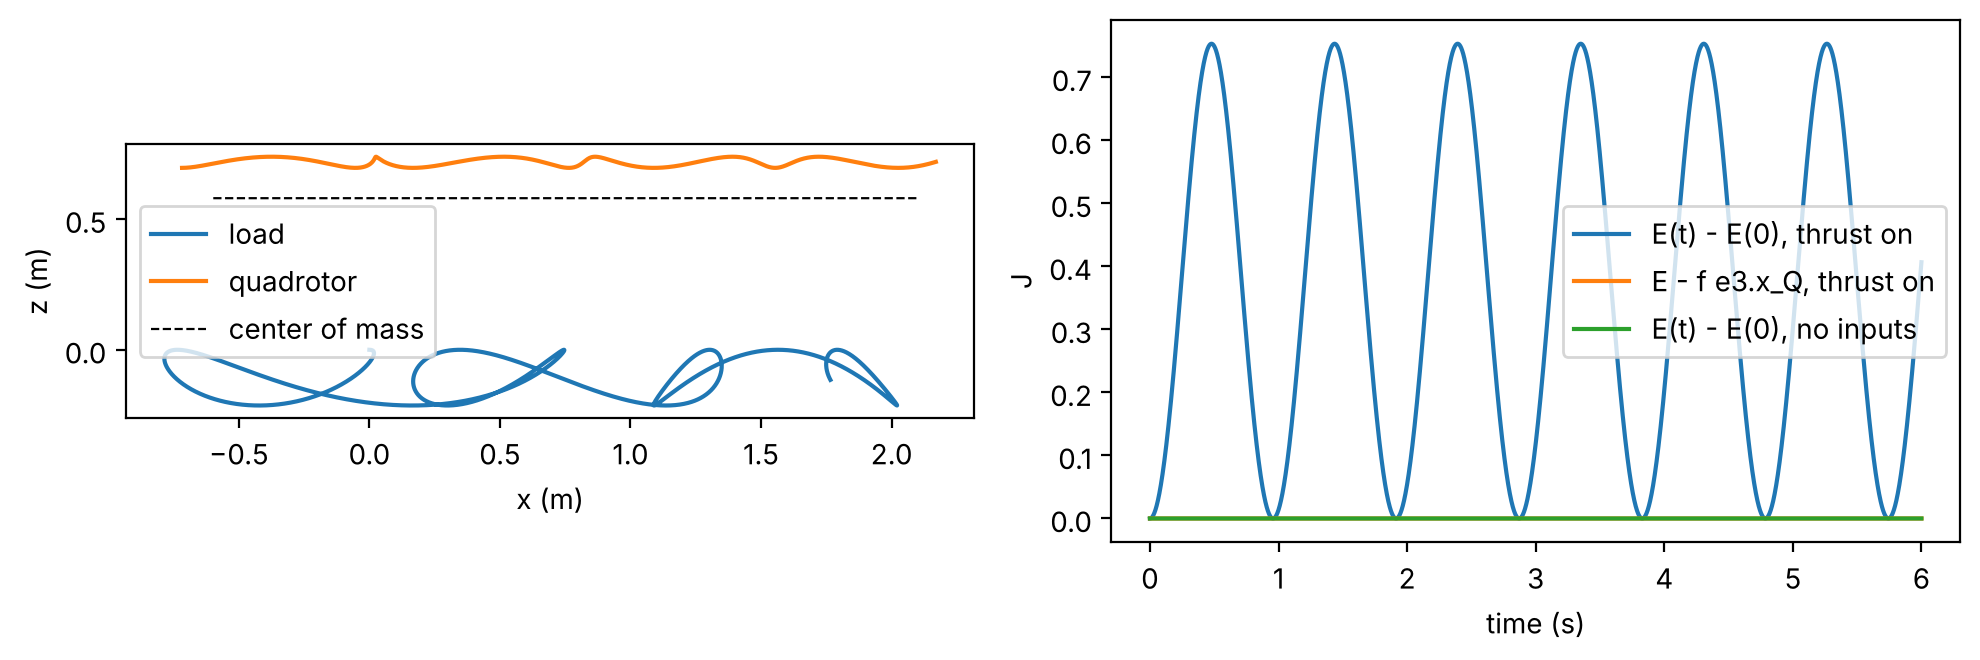

constraint drift, forced run: 3.774758283725532e-15


In [7]:
xQ_t = traj["x_L"] - p["l"] * traj["q"]
com = (p["m_Q"] * xQ_t + p["m_L"] * traj["x_L"]) / (p["m_Q"] + p["m_L"])
Ef = traj.energy()
work = hover[0] * (xQ_t[:, 2] - xQ_t[0, 2])

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3.4))
ax0.plot(traj["x_L"][:, 0], traj["x_L"][:, 2], label="load")
ax0.plot(xQ_t[:, 0], xQ_t[:, 2], label="quadrotor")
ax0.plot(com[:, 0], com[:, 2], "k--", lw=0.8, label="center of mass")
ax0.set_xlabel("x (m)")
ax0.set_ylabel("z (m)")
ax0.set_aspect("equal")
ax0.legend()
ax1.plot(traj.t, Ef - Ef[0], label="E(t) - E(0), thrust on")
ax1.plot(traj.t, Ef - work - Ef[0], label="E - f e3.x_Q, thrust on")
ax1.plot(free.t, E - E[0], label="E(t) - E(0), no inputs")
ax1.set_xlabel("time (s)")
ax1.set_ylabel("J")
ax1.legend()
plt.tight_layout()
plt.show()
print("constraint drift, forced run:", traj.max_drift())

Compare with the hand-derived model of Wu (2017), eq. (3.4):
$(m_Q+m_L)(\ddot x_L + g e_3) = (q\cdot fRe_3 - m_Q l\,\|\dot q\|^2)\,q$, $\ m_Q l\,\dot\omega = -q\times fRe_3$,
$\ J\dot\Omega + \Omega\times J\Omega = \tau$.

In [8]:
from geomech.simulation import accelerations


def wu_accelerations(qv, wv, Rm, Om, fv, tauv):
    F = fv * Rm[:, 2]
    qd = np.cross(wv, qv)
    aL_ = (qv @ F - p["m_Q"] * p["l"] * qd @ qd) * qv / (p["m_Q"] + p["m_L"]) - p["g"] * p["e3"]
    dw = -np.cross(qv, F) / (p["m_Q"] * p["l"])
    dOm = np.linalg.solve(p["J"], tauv - np.cross(Om, p["J"] @ Om))
    return np.r_[aL_, dw, dOm]


worst = 0.0
for _ in range(50):
    qv = rng.normal(size=3)
    qv /= np.linalg.norm(qv)
    wv = np.cross(qv, rng.normal(size=3))
    Rm = np.linalg.qr(rng.normal(size=(3, 3)))[0]
    Rm *= np.sign(np.linalg.det(Rm))
    Om = rng.normal(size=3)
    uv = np.r_[rng.uniform(5, 30), rng.normal(size=3)]
    state = layout.pack(x_L=rng.normal(size=3), q=qv, R=Rm, x_L_dot=rng.normal(size=3), omega_q=wv, Omega_R=Om)
    diff = accelerations(plant, state, uv, p) - wu_accelerations(qv, wv, Rm, Om, uv[0], uv[1:])
    worst = max(worst, float(np.max(np.abs(diff))))
print("largest difference from the thesis equations:", worst)

largest difference from the thesis equations: 3.197442310920451e-14


## 4. One pendulum, every stage (Section 5.3)

The same pipeline on the smallest curved example, with a trace that keeps every intermediate expression.

In [9]:
from geomech import *

half = Scalar("0.5", value=0.5, attr=["Constant"])
m, g, l = getScalars("m g l", attr=["Constant"])
e3 = Vector("e3", attr=["Constant"])
q, tau = S2("q"), Vector("\\tau")               # rod direction, torque at the pivot
omega, xi = q.get_tangent_vector(), q.get_variation_vector()

L = half * m * l * l * Dot(omega, omega) - m * g * l * Dot(q, e3)
dW = Dot(xi, tau)
variables = SystemVariables(vectors=[q])

trace = EOMTrace()
eom = compute_eom(L, dW, variables, trace=trace)

trace.summary(chars=95)

dL                                       31 nodes  (0.5·m*·l*·l*·(<δ(v:\omega_{q}), v:\omega_{q}> + <v:\omega_{q}, δ(v:\omega_{q})>) -m*·g*·l*·...
dW                                        3 nodes  <v:\xi_{q}, v:\tau>
dS                                       34 nodes  (0.5·m*·l*·l*·(<δ(v:\omega_{q}), v:\omega_{q}> + <v:\omega_{q}, δ(v:\omega_{q})>) -m*·g*·l*·...
manifold_rules                           46 nodes  (0.5·m*·l*·l*·(<(d/dt(v:\xi_{q}) + cross(v:\omega_{q}, v:\xi_{q})·(-2)), v:\omega_{q}> + <v:...
simplify                                 27 nodes  (m*·l*·l*·<d/dt(v:\xi_{q}), v:\omega_{q}> -m*·g*·l*·<cross(v:\xi_{q}, S2:q), v:e3*> + <v:\xi...
ibp.prepare                              27 nodes  (m*·l*·l*·<d/dt(v:\xi_{q}), v:\omega_{q}> -m*·g*·l*·<cross(v:\xi_{q}, S2:q), v:e3*> + <v:\xi...
ibp.collect[\frac{d}{dt}(\xi_{q})]       27 nodes  (m*·l*·l*·<d/dt(v:\xi_{q}), v:\omega_{q}> -m*·g*·l*·<cross(v:\xi_{q}, S2:q), v:e3*> + <v:\xi...
ibp.integrate[\frac{d}{dt}(\xi_{q})]     29 nod

In [10]:
for stage in ["dS", "manifold_rules", "simplify", "ibp", "equation[\\xi_{q}]"]:
    print(f"{stage:22s}", to_latex(trace[stage]))

dS                     \left(\frac{1}{2} m l l \left(\delta \omega_{q} \cdot \omega_{q} + \omega_{q} \cdot \delta \omega_{q}\right) -m g l \left(\xi_{q} \times q \cdot e3\right) + \xi_{q} \cdot \tau\right)
manifold_rules         \left(\frac{1}{2} m l l \left(\left(\dot{\xi_{q}} -2 \left(\omega_{q} \times \xi_{q}\right)\right) \cdot \omega_{q} + \omega_{q} \cdot \left(\dot{\xi_{q}} -2 \left(\omega_{q} \times \xi_{q}\right)\right)\right) -m g l \left(\xi_{q} \times q \cdot e3\right) + \xi_{q} \cdot \tau\right)
simplify               \left(m l l \left(\dot{\xi_{q}} \cdot \omega_{q}\right) -m g l \left(\xi_{q} \times q \cdot e3\right) + \xi_{q} \cdot \tau\right)
ibp                    \left(-m l l \left(\xi_{q} \cdot \dot{\omega_{q}}\right) -m g l \left(\xi_{q} \times q \cdot e3\right) + \xi_{q} \cdot \tau\right)
equation[\xi_{q}]      \left(-m l l \dot{\omega_{q}} -m g l \left(q \times e3\right) + \tau\right)


Every rewrite has a name. Turn the rule log on and count.

In [11]:
buf = io.StringIO()
handler = logging.StreamHandler(buf)
logging.getLogger("geomech.rules").addHandler(handler)
set_trace(True)
compute_eom(L, dW, variables)
set_trace(False)
logging.getLogger("geomech.rules").removeHandler(handler)
lines = buf.getvalue().splitlines()
print(len(lines), "rule applications. The first ten:")
for ln in lines[:10]:
    print("  ", ln[:110])

44 rule applications. The first ten:
   manifold.s2_variation_omega: δ(v:\omega_{q}) ==> (d/dt(v:\xi_{q}) + cross(v:\omega_{q}, v:\xi_{q})·(-2))
   manifold.s2_variation_omega: δ(v:\omega_{q}) ==> (d/dt(v:\xi_{q}) + cross(v:\omega_{q}, v:\xi_{q})·(-2))
   expand.dot_over_vadd: <(d/dt(v:\xi_{q}) + cross(v:\omega_{q}, v:\xi_{q})·(-2)), v:\omega_{q}> ==> (<d/dt(v:\xi
   expand.dot_over_vadd: <v:\omega_{q}, (d/dt(v:\xi_{q}) + cross(v:\omega_{q}, v:\xi_{q})·(-2))> ==> (<v:\omega_{
   expand.mul_over_add: 0.5·m*·l*·l*·(<(d/dt(v:\xi_{q}) + cross(v:\omega_{q}, v:\xi_{q})·(-2)), v:\omega_{q}> + <
   pull.dot_scaled: <cross(v:\omega_{q}, v:\xi_{q})·(-2), v:\omega_{q}> ==> (-2)·<cross(v:\omega_{q}, v:\xi_{q}),
   pull.dot_scaled: <v:\omega_{q}, cross(v:\omega_{q}, v:\xi_{q})·(-2)> ==> (-2)·<v:\omega_{q}, cross(v:\omega_{q
   vector.dot_cross_orthogonal: <cross(v:\omega_{q}, v:\xi_{q}), v:\omega_{q}> ==> 0
   vector.dot_cross_orthogonal: <v:\omega_{q}, cross(v:\omega_{q}, v:\xi_{q})> ==> 0
   simp

The tree itself: `print_tree` shows the object behind Figure 5.1.

In [12]:
print_tree(L, style="indent")

Add
  ├─ 0: Mul
    ├─ L: Mul
      ├─ L: Mul
        ├─ L: Mul
          ├─ L: Scalar('0.5', value=0.5, is_constant, is_numeric)
          ├─ R: Scalar('m', is_constant)
        ├─ R: Scalar('l', is_constant)
      ├─ R: Scalar('l', is_constant)
    ├─ R: Dot
      ├─ L: TS2('\omega_{q}', of=S2 'q')
      ├─ R: TS2('\omega_{q}', of=S2 'q')
  ├─ 1: Mul
    ├─ L: Mul
      ├─ L: Mul
        ├─ L: Mul
          ├─ L: Scalar('m', is_constant)
          ├─ R: Scalar('g', is_constant)
        ├─ R: Scalar('l', is_constant)
      ├─ R: Dot
        ├─ L: S2('q', is_unit_norm, is_manifold)
        ├─ R: Vector('e3', is_constant)
    ├─ R: Scalar('(-1)', value=-1, is_constant, is_numeric)

expr: (0.5·m*·l*·l*·<v:\omega_{q}, v:\omega_{q}> -m*·g*·l*·<S2:q, v:e3*>)


## 5. More bodies (Section 5.6)

A chain of $n$ spherical pendulums with $n$ symbolic, then instantiated for $n = 1, \dots, 6$.

In [13]:
from geomech.indexed import (Family, IndexedVariables, Sum, compute_indexed_eom,
                             indices, n)

i, j = indices("i j")
g, e3 = Scalar("g", attr=["Constant"]), Vector("e3", attr=["Constant"])
q = Family(S2, "q")                               # q_1, ..., q_n
m = Family(Scalar, "m", attr=["Constant"])
l = Family(Scalar, "l", attr=["Constant"])


def x(k):                                         # position of mass k
    return Sum(j, 1, k, q[j] * l[j])


v = x(i).t_diff()
L = Sum(i, 1, n, 0.5 * m[i] * v.dot(v)) - Sum(i, 1, n, m[i] * g * x(i).dot(e3))
chain = IndexedVariables(families=[q])
eom = compute_indexed_eom(L, None, chain)

for size in range(1, 7):
    members, eq = chain.members(size), eom.instantiate(size)
    print(size, check_eom(L.instantiate(size), None, members, eq))

1 6.2314291732746e-09


2 4.9374584443931414e-08


3 3.203552817684851e-08


4 6.362833548612062e-08


5 1.037956189378504e-07


6 1.1306899280509194e-07


In [14]:
print(eom["q"].to_latex())

\sum_{j=i}^{n} \left(-l_{i} m_{j} g \left(q_{i} \times e3\right)\right) + \sum_{j=1}^{n} \sum_{k=\max(i, j)}^{n} \left(\left(-m_{k} l_{i} l_{j} \left(\left(\omega_{q_{i}} \times q_{i}\right) \times \left(\omega_{q_{j}} \times q_{j}\right)\right) -m_{k} l_{i} l_{j} \left(q_{i} \times \left(\dot{\omega_{q_{j}}} \times q_{j}\right)\right) + m_{k} l_{i} l_{j} \left(\omega_{q_{j}} \cdot \omega_{q_{j}}\right) \left(q_{i} \times q_{j}\right) + 2 m_{k} l_{i} l_{j} \left(\omega_{q_{i}} \times \left(q_{i} \times \left(\omega_{q_{j}} \times q_{j}\right)\right)\right) -m_{k} l_{i} l_{j} \left(q_{i} \times \left(\omega_{q_{i}} \times \left(\omega_{q_{j}} \times q_{j}\right)\right)\right)\right)\right) = 0


energy drift: 2.594571918423938e-08  constraint drift: 6.439293542825908e-15


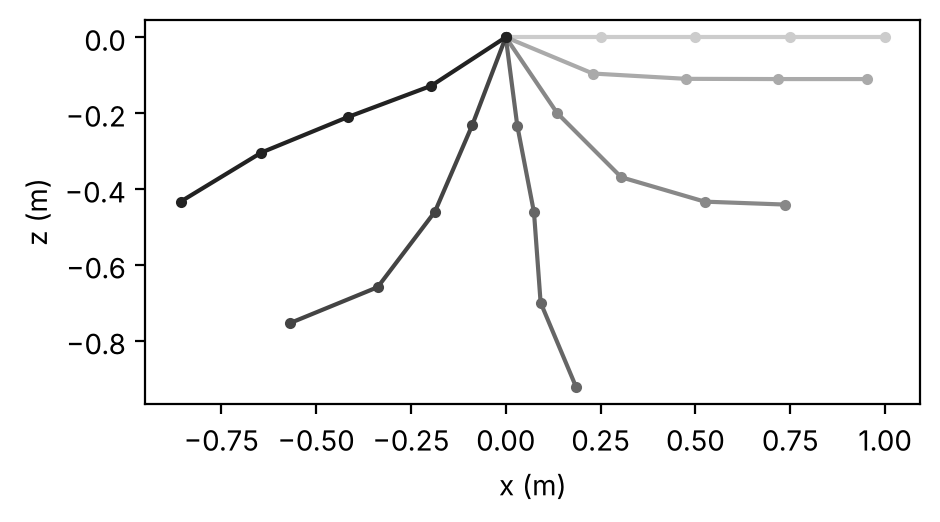

In [15]:
size = 4
members, L4 = chain.members(size), L.instantiate(size)
sf4 = to_standard_form(eom.instantiate(size), members, [])
layout4 = StateLayout(members, [], collect_params([L4], members, []))
plant4 = load_module(module_source(sf4, layout4, lagrangian=L4), "chain4")
p4 = {"g": 9.81, "e3": np.array([0.0, 0.0, 1.0])}
p4.update({f"m_{{{k}}}": 0.25 for k in range(1, size + 1)})
p4.update({f"l_{{{k}}}": 0.25 for k in range(1, size + 1)})
x04 = layout4.pack(**{f"q_{k}": [1.0, 0.0, 0.0] for k in range(1, size + 1)},
                   **{f"omega_q_{k}": [0.0, 0.0, 0.6 * k] for k in range(1, size + 1)})
tr4 = simulate(plant4, x04, 2.0, p4)
E4 = tr4.energy()
print("energy drift:", np.max(np.abs(E4 - E4[0])) / max(abs(E4[0]), 1.0), " constraint drift:", tr4.max_drift())

joints = np.zeros((len(tr4.t), size + 1, 3))
for k in range(1, size + 1):
    joints[:, k] = joints[:, k - 1] + 0.25 * tr4[f"q_{k}"]
plt.figure(figsize=(5, 3.4))
for idx in range(0, 900, 150):
    plt.plot(joints[idx, :, 0], joints[idx, :, 2], "o-", ms=3, color=str(0.8 - 0.8 * idx / 900))
plt.gca().set_aspect("equal")
plt.xlabel("x (m)")
plt.ylabel("z (m)")
plt.show()

## Starting points for the exercises

**Exercise 5.3.** The 3D pendulum on $\mathrm{SO}(3)$. Run it with a trace and find the stage where the term from
$\delta\Omega = \dot\eta + \Omega\times\eta$ survives.

In [16]:
half = Scalar("0.5", value=0.5, attr=["Constant"])
m, g = getScalars("m g", attr=["Constant"])
J = Matrix("J", attr=["Constant", "SymmetricMatrix"])
rho, e3 = Vector("\\rho", attr=["Constant"]), Vector("e3", attr=["Constant"])
R, tau = SO3("R"), Vector("\\tau")
Omega, eta = R.get_tangent_vector(), R.get_variation_vector()
L = half * Dot(Omega, J * Omega) - m * g * Dot(e3, R * rho)
dW = Dot(eta, tau)
variables = SystemVariables(matrices=[R])
trace = EOMTrace()
eom = compute_eom(L, dW, variables, trace=trace)
trace.summary(chars=95)
print_eom(eom)
print("check_eom error:", check_eom(L, dW, variables, eom, inputs=[tau]))

dL                                        30 nodes  (0.5·(<δ(v:\Omega_{R}), M:J*·v:\Omega_{R}> + <v:\Omega_{R}, M:J*·δ(v:\Omega_{R})>) -m*·g*·<v...
dW                                         3 nodes  <v:\eta_{R}, v:\tau>
dS                                        33 nodes  (0.5·(<δ(v:\Omega_{R}), M:J*·v:\Omega_{R}> + <v:\Omega_{R}, M:J*·δ(v:\Omega_{R})>) -m*·g*·<v...
manifold_rules                            41 nodes  (0.5·(<(d/dt(v:\eta_{R}) + cross(v:\Omega_{R}, v:\eta_{R})), M:J*·v:\Omega_{R}> + <v:\Omega_...
simplify                                  51 nodes  (<d/dt(v:\eta_{R}), M:J*·v:\Omega_{R}>·(0.5) + <cross(v:\Omega_{R}, v:\eta_{R}), M:J*·v:\Ome...
ibp.prepare                               51 nodes  (<d/dt(v:\eta_{R}), M:J*·v:\Omega_{R}>·(0.5) + <cross(v:\Omega_{R}, v:\eta_{R}), M:J*·v:\Ome...
ibp.collect[\frac{d}{dt}(\eta_{R})]       52 nodes  (<d/dt(v:\eta_{R}), M:J*·v:\Omega_{R}>·(0.5) + <cross(v:\Omega_{R}, v:\eta_{R}), M:J*·v:\Ome...
ibp.integrate[\frac{d}{dt}(\eta_{R})]  

**Exercise 5.5.** Plant your own error. `eom` is a dictionary `{name: (variation, E)}`. Replace one `E` by an
expression of your own and run `check_eom`. Start from the listing in part 2.

**Exercise 5.6.** The library's catalog has the elastic cable ready made. Compare its Lagrangian with yours.

In [17]:
import geomech.systems

elastic = geomech.systems.get("quadrotor_elastic_load")
eom_e = compute_eom(elastic.L, elastic.dW, elastic.variables)
print(len(eom_e), "equations, keyed by", list(eom_e))
print("check_eom error:", check_eom(elastic.L, elastic.dW, elastic.variables, eom_e, inputs=elastic.inputs))

4 equations, keyed by ['\\delta{l}', '\\delta{x_L}', '\\xi_{q}', '\\eta_{R}']


check_eom error: 1.3717498230849837e-07
